## 1. Install/import libraries and load the dataset

In [2]:

# !pip -q install statsmodels scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Google Colab: upload DailyDelhiClimateTrain.csv when prompted.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    if csv_name is None:
        raise FileNotFoundError("No CSV file uploaded.")
    raw = pd.read_csv(csv_name)
except ImportError:
    # Local Jupyter fallback: place the CSV in the same folder as this notebook.
    raw = pd.read_csv("DailyDelhiClimateTrain.csv")

print("Shape:", raw.shape)
display(raw.head())
print("\nColumns:", raw.columns.tolist())


Saving DailyDelhiClimateTrain.csv to DailyDelhiClimateTrain (1).csv
Shape: (1462, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000



Columns: ['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure']


## 2. Clean, inspect and prepare monthly mean temperature

In [6]:
# Expected columns include date and meantemp.
raw.columns = [str(c).strip() for c in raw.columns]

# If 'date' is already the index, reset it so the rest of the code works cleanly
if "date" not in raw.columns and raw.index.name == "date":
    raw = raw.reset_index()

if "date" not in raw.columns or "meantemp" not in raw.columns:
    raise ValueError("Expected columns 'date' and 'meantemp'. Check the uploaded CSV.")

raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
raw["meantemp"] = pd.to_numeric(raw["meantemp"], errors="coerce")
raw = raw.dropna(subset=["date", "meantemp"]).sort_values("date")
raw = raw.drop_duplicates(subset="date").set_index("date")

print("Date range:", raw.index.min().date(), "to", raw.index.max().date())
print("Daily observations:", len(raw))
print("Missing values in meantemp:", int(raw["meantemp"].isna().sum()))
print(raw["meantemp"].describe())

# Monthly average temperature; month-end timestamps preserve chronological order.
monthly = raw["meantemp"].resample("ME").mean().dropna()
monthly.name = "mean_temperature"

print("\nMonthly observations:", len(monthly))
display(monthly.head())

Date range: 2013-01-01 to 2017-01-01
Daily observations: 1462
Missing values in meantemp: 0
count    1462.000000
mean       25.495521
std         7.348103
min         6.000000
25%        18.857143
50%        27.714286
75%        31.305804
max        38.714286
Name: meantemp, dtype: float64

Monthly observations: 49


,mean_temperature
date,
2013-01-31,12.074770
2013-02-28,16.867560
2013-03-31,22.814209
2013-04-30,28.895119
2013-05-31,33.776767


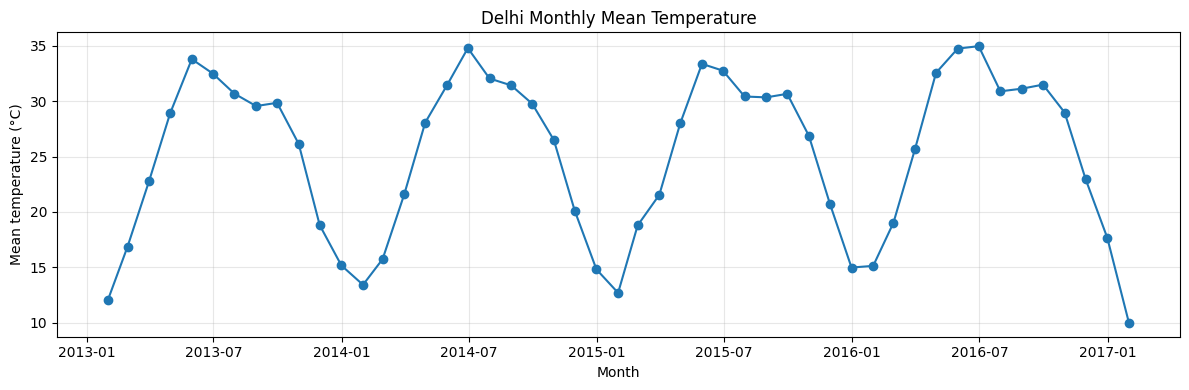

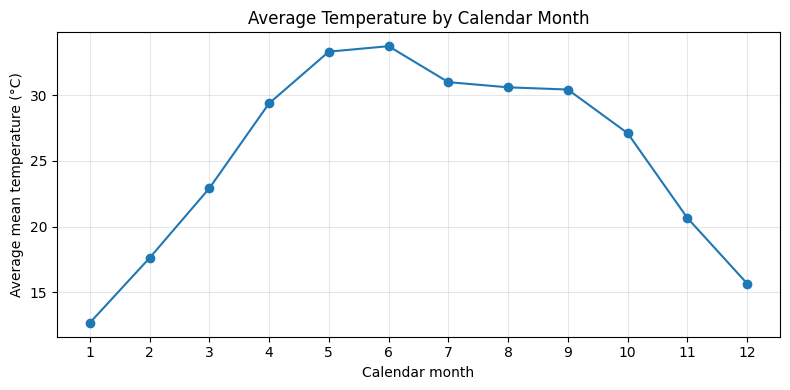

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly, marker="o", linewidth=1.5)
plt.title("Delhi Monthly Mean Temperature")
plt.xlabel("Month")
plt.ylabel("Mean temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Seasonal pattern by calendar month
seasonal_profile = monthly.groupby(monthly.index.month).mean()
plt.figure(figsize=(8, 4))
plt.plot(seasonal_profile.index, seasonal_profile.values, marker="o")
plt.xticks(range(1, 13))
plt.title("Average Temperature by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Average mean temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Train/test split

The last 12 monthly observations are held out as the test set. The models are fitted only on earlier observations. This is a chronological split, which is appropriate for forecasting.

Training observations: 37
Testing observations: 12
Test period: 2016-02-29 to 2017-01-31


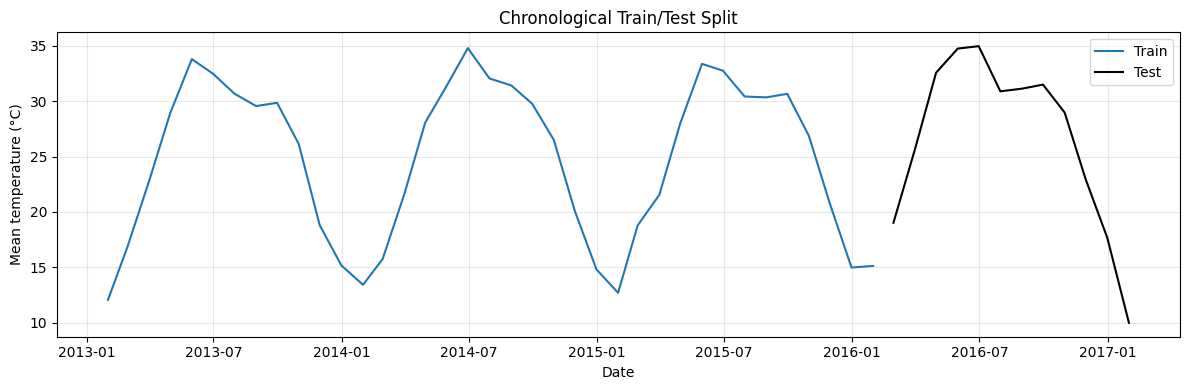

In [8]:
test_size = min(12, max(6, len(monthly) // 4))
train = monthly.iloc[:-test_size].astype(float)
test = monthly.iloc[-test_size:].astype(float)

print(f"Training observations: {len(train)}")
print(f"Testing observations: {len(test)}")
print("Test period:", test.index.min().date(), "to", test.index.max().date())

plt.figure(figsize=(12, 4))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test", color="black")
plt.title("Chronological Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Mean temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Stationarity checks and differencing


Original training series
ADF statistic: -1.8858; p-value: 0.3388
KPSS statistic: 0.0424; p-value: 0.1000
ADF null hypothesis: unit root (non-stationary).
KPSS null hypothesis: stationary.

First-differenced training series
ADF statistic: -7.5120; p-value: 0.0000
KPSS statistic: 0.1309; p-value: 0.1000
ADF null hypothesis: unit root (non-stationary).
KPSS null hypothesis: stationary.


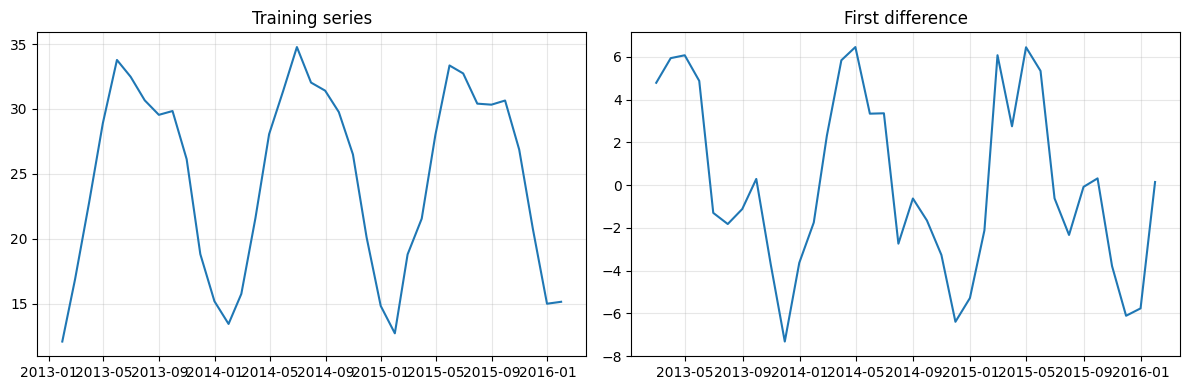

In [9]:
def stationarity_report(series, label):
    series = pd.Series(series).dropna()
    print(f"\n{label}")
    adf_result = adfuller(series, autolag="AIC")
    print(f"ADF statistic: {adf_result[0]:.4f}; p-value: {adf_result[1]:.4f}")
    try:
        kpss_result = kpss(series, regression="c", nlags="auto")
        print(f"KPSS statistic: {kpss_result[0]:.4f}; p-value: {kpss_result[1]:.4f}")
    except Exception as exc:
        print("KPSS could not be calculated:", exc)
    print("ADF null hypothesis: unit root (non-stationary).")
    print("KPSS null hypothesis: stationary.")

stationarity_report(train, "Original training series")
diff_train = train.diff().dropna()
stationarity_report(diff_train, "First-differenced training series")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train)
axes[0].set_title("Training series")
axes[1].plot(diff_train)
axes[1].set_title("First difference")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


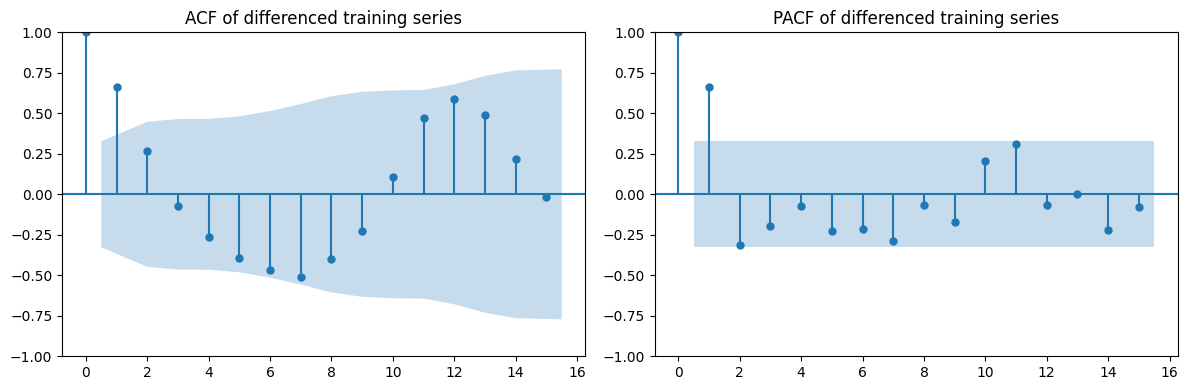

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_train, ax=axes[0], lags=min(15, len(diff_train)//2 - 1))
plot_pacf(diff_train, ax=axes[1], lags=min(15, len(diff_train)//2 - 1), method="ywm")
axes[0].set_title("ACF of differenced training series")
axes[1].set_title("PACF of differenced training series")
plt.tight_layout()
plt.show()


## 5. Fit AR, MA and ARMA models



In [11]:
def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    # MAPE can be unstable near zero; temperatures in this dataset are generally not near zero.
    mape = np.mean(np.abs((actual - predicted) / np.where(np.abs(actual) < 1e-8, np.nan, actual))) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

h = len(test)
d_train = train.diff().dropna()
last_train_value = train.iloc[-1]

results = []
forecast_store = {}

# AR(p): AutoReg on differenced values
for p in [1, 2, 3]:
    try:
        fit = AutoReg(d_train, lags=p, trend="c", old_names=False).fit()
        diff_forecast = fit.predict(start=len(d_train), end=len(d_train) + h - 1, dynamic=False)
        pred = pd.Series(last_train_value + np.cumsum(np.asarray(diff_forecast)), index=test.index)
        metrics = forecast_metrics(test, pred)
        results.append({"Model": f"AR({p}) on difference", **metrics})
        forecast_store[f"AR({p}) on difference"] = pred
    except Exception as e:
        print(f"AR({p}) failed:", e)

# MA(q) and ARMA(p,q) are represented as ARIMA(p,0,q) on the differenced series.
for q in [1, 2, 3]:
    try:
        fit = ARIMA(d_train, order=(0, 0, q), trend="c").fit()
        diff_forecast = fit.forecast(steps=h)
        pred = pd.Series(last_train_value + np.cumsum(np.asarray(diff_forecast)), index=test.index)
        metrics = forecast_metrics(test, pred)
        results.append({"Model": f"MA({q}) on difference", **metrics})
        forecast_store[f"MA({q}) on difference"] = pred
    except Exception as e:
        print(f"MA({q}) failed:", e)

for p, q in [(1, 1), (1, 2), (2, 1), (2, 2)]:
    try:
        fit = ARIMA(d_train, order=(p, 0, q), trend="c").fit()
        diff_forecast = fit.forecast(steps=h)
        pred = pd.Series(last_train_value + np.cumsum(np.asarray(diff_forecast)), index=test.index)
        metrics = forecast_metrics(test, pred)
        results.append({"Model": f"ARMA({p},{q}) on difference", **metrics})
        forecast_store[f"ARMA({p},{q}) on difference"] = pred
    except Exception as e:
        print(f"ARMA({p},{q}) failed:", e)

pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)


AR(1) failed: AutoReg.__init__() got an unexpected keyword argument 'old_names'
AR(2) failed: AutoReg.__init__() got an unexpected keyword argument 'old_names'
AR(3) failed: AutoReg.__init__() got an unexpected keyword argument 'old_names'


,Model,MAE,RMSE,MAPE (%)
0,"ARMA(2,2) on difference",3.225068,3.846622,15.424740
1,"ARMA(2,1) on difference",3.863538,5.166291,21.289273
2,MA(3) on difference,9.145458,10.176325,37.004259
3,"ARMA(1,2) on difference",9.258061,10.290611,37.352216
4,MA(2) on difference,9.760592,10.866694,38.029481
5,"ARMA(1,1) on difference",10.026745,11.129780,39.103275
6,MA(1) on difference,10.747334,12.090567,39.682094


## 6. Fit ARIMA and SARIMA models

In [12]:
# ARIMA(p,d,q) on the temperature level series.
for order in [(1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 1)]:
    try:
        fit = ARIMA(train, order=order, trend="t" if order[1] == 1 else "c").fit()
        pred = fit.forecast(steps=h)
        pred.index = test.index
        name = f"ARIMA{order}"
        metrics = forecast_metrics(test, pred)
        results.append({"Model": name, **metrics})
        forecast_store[name] = pred
    except Exception as e:
        print(f"ARIMA{order} failed:", e)

# SARIMA: annual seasonality in monthly data (m=12).
# Limited candidate orders are intentional because the dataset is short.
for order, seasonal_order in [
    ((1, 1, 1), (1, 0, 0, 12)),
    ((1, 1, 0), (1, 0, 0, 12)),
    ((0, 1, 1), (1, 0, 0, 12)),
]:
    try:
        fit = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)
        pred = fit.forecast(steps=h)
        pred.index = test.index
        name = f"SARIMA{order}x{seasonal_order}"
        metrics = forecast_metrics(test, pred)
        results.append({"Model": name, **metrics})
        forecast_store[name] = pred
    except Exception as e:
        print(f"SARIMA {order} x {seasonal_order} failed:", e)

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)


,Model,MAE,RMSE,MAPE (%)
0,"SARIMA(1, 1, 0)x(1, 0, 0, 12)",1.687391,2.503241,9.765622
1,"SARIMA(1, 1, 1)x(1, 0, 0, 12)",2.182156,2.722092,11.026109
2,"SARIMA(0, 1, 1)x(1, 0, 0, 12)",2.195555,2.732907,11.082059
3,"ARMA(2,2) on difference",3.225068,3.846622,15.424740
4,"ARMA(2,1) on difference",3.863538,5.166291,21.289273
5,"ARIMA(2, 1, 1)",3.864033,5.166331,21.289704
6,MA(3) on difference,9.145458,10.176325,37.004259
7,"ARMA(1,2) on difference",9.258061,10.290611,37.352216
8,MA(2) on difference,9.760592,10.866694,38.029481
9,"ARMA(1,1) on difference",10.026745,11.129780,39.103275


## 7. Forecast comparison and best model

Best model by held-out RMSE: SARIMA(1, 1, 0)x(1, 0, 0, 12)
This is the best among the candidate models tested on this single test window.


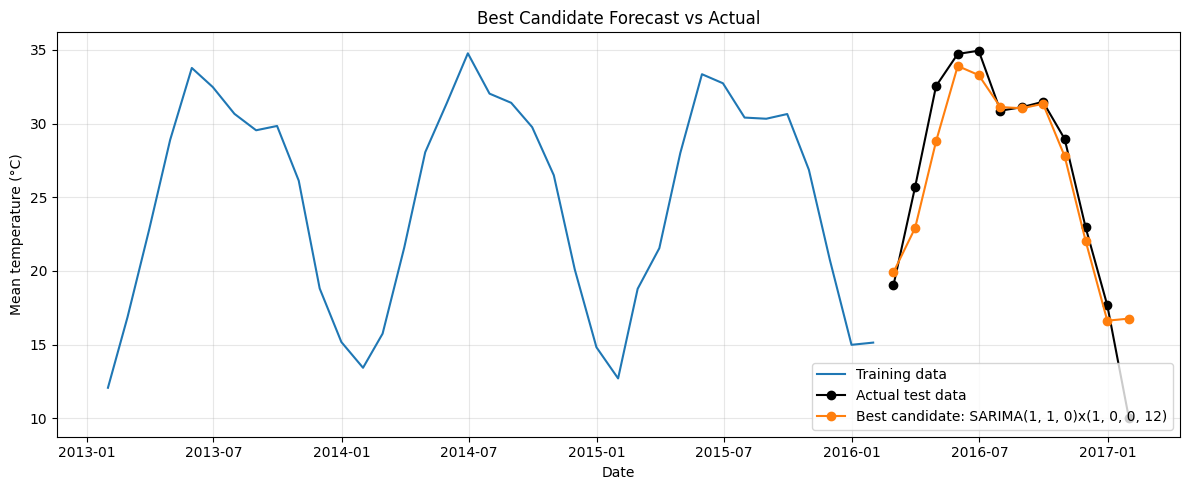

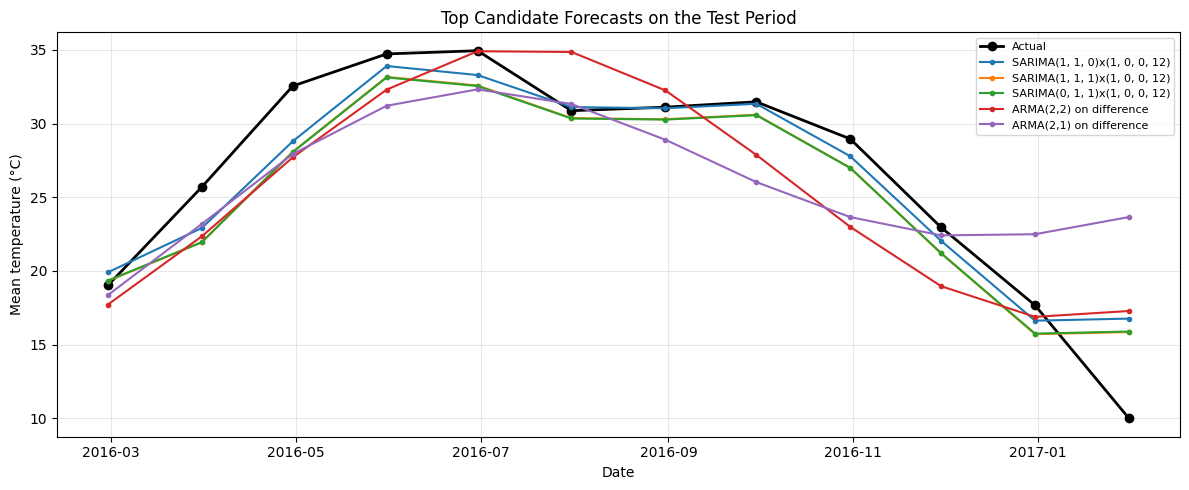

In [13]:
if not forecast_store:
    raise RuntimeError("No models fitted successfully. Check the data and package versions.")

best_name = results_df.iloc[0]["Model"]
best_pred = forecast_store[best_name]
print("Best model by held-out RMSE:", best_name)
print("This is the best among the candidate models tested on this single test window.")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data", marker="o", color="black")
plt.plot(best_pred.index, best_pred, label=f"Best candidate: {best_name}", marker="o")
plt.title("Best Candidate Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Mean temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot the top five model forecasts
top_names = results_df["Model"].head(5).tolist()
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Actual", color="black", marker="o", linewidth=2)
for name in top_names:
    plt.plot(forecast_store[name].index, forecast_store[name], marker=".", label=name)
plt.title("Top Candidate Forecasts on the Test Period")
plt.xlabel("Date")
plt.ylabel("Mean temperature (°C)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Residual diagnostics for the best model



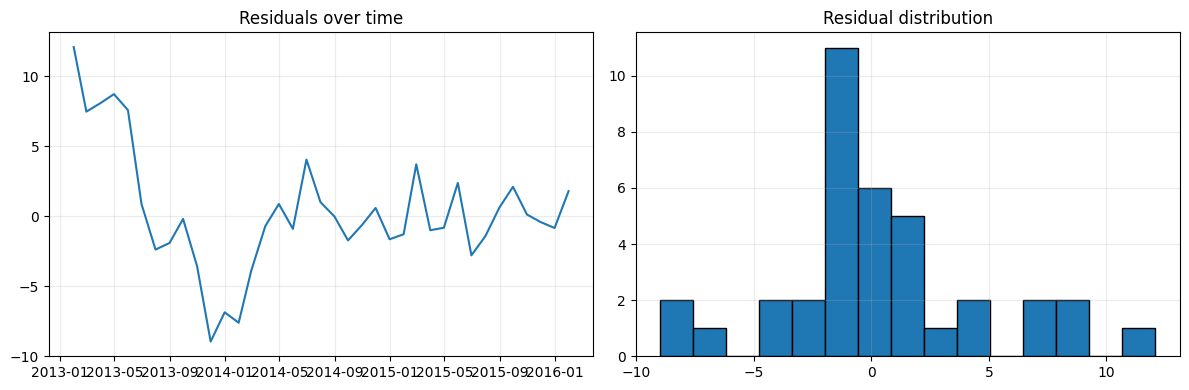

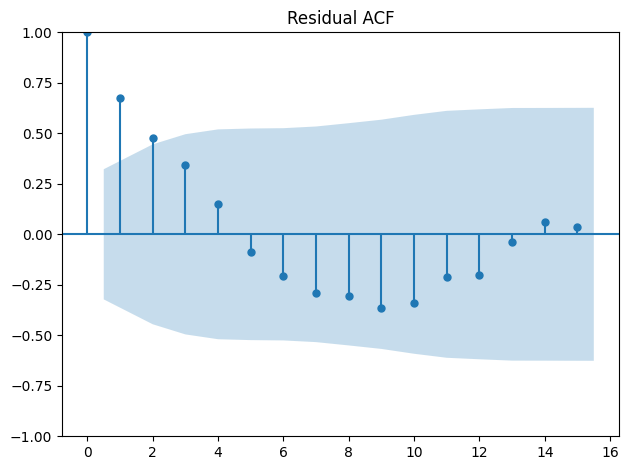

In [14]:
# Refit the selected model on training data to inspect in-sample residuals.
# Map the chosen model name back to a compatible model specification.
if best_name.startswith("ARIMA"):
    import ast
    order_text = best_name[len("ARIMA"):]
    best_order = ast.literal_eval(order_text)
    diagnostic_fit = ARIMA(train, order=best_order, trend="t" if best_order[1] == 1 else "c").fit()
elif best_name.startswith("SARIMA"):
    # Parse the name produced above, e.g. SARIMA(1, 1, 1)x(1, 0, 0, 12)
    import re, ast
    match = re.match(r"SARIMA(\([^)]*\))x(\([^)]*\))", best_name)
    order = ast.literal_eval(match.group(1))
    seasonal_order = ast.literal_eval(match.group(2))
    diagnostic_fit = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                              trend="n", enforce_stationarity=False,
                              enforce_invertibility=False).fit(disp=False, maxiter=200)
else:
    diagnostic_fit = None

if diagnostic_fit is not None:
    residuals = pd.Series(diagnostic_fit.resid).dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(residuals)
    axes[0].set_title("Residuals over time")
    axes[1].hist(residuals, bins=15, edgecolor="black")
    axes[1].set_title("Residual distribution")
    for ax in axes:
        ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
    plot_acf(residuals, lags=min(15, len(residuals)//2 - 1))
    plt.title("Residual ACF")
    plt.tight_layout()
    plt.show()
else:
    print("Residual refit is not automatically implemented for the differenced AR/MA/ARMA candidate.")
    print("Interpret the selected model's test metrics and forecast plot, and inspect residuals for ARIMA/SARIMA candidates if applicable.")


In [15]:
monthly.to_csv("delhi_monthly_mean_temperature.csv", header=True)
results_df.to_csv("univariate_model_comparison.csv", index=False)
print("Saved: delhi_monthly_mean_temperature.csv")
print("Saved: univariate_model_comparison.csv")


Saved: delhi_monthly_mean_temperature.csv
Saved: univariate_model_comparison.csv
